In [12]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('social_media_engagement_5000.csv')

# Inspect basic structure & convert data types
print(df.info())
# Convert date columns (assuming a column named 'date' exists)
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])

likes_array = np.array(df['likes'])
print("Mean Likes (NumPy):", np.mean(likes_array))
print("Max Likes (NumPy):", np.max(likes_array))

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [13]:
# 1. Missing Values
print(df.isnull().sum())
df['likes'].fillna(df['likes'].median(), inplace=True)
df['comments'].fillna(df['comments'].mode()[0], inplace=True)
df.dropna(subset=['post_type'], inplace=True)

# 2. Duplicate Handling
df.drop_duplicates(inplace=True)

# 3. Standardize Categories & Values
if 'gender' in df.columns:
    df['gender'] = df['gender'].str.lower().str.strip()
# Correct unrealistic negative or extreme values
df = df[df['likes'] >= 0]
df = df[df['comments'] >= 0]

# 4. Feature Cleaning: Extract hashtag count
if 'caption' in df.columns:
    df['hashtag_count'] = df['caption'].str.findall(r'#(\w+)').str.len()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


C:\Users\ACER\AppData\Local\Temp\ipykernel_13000\2829382564.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['likes'].fillna(df['likes'].median(), inplace=True)
C:\Users\ACER\AppData\Local\Temp\ipykernel_13000\2829382564.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assign

In [14]:
print(df.head())
print(df.tail())
print(df.shape)
print(df.describe())

# Categorical distributions
print(df['post_type'].value_counts())

# Correlation Matrix
numeric_cols = ['likes', 'comments', 'shares', 'impressions', 'watch_time', 'followers']
corr_matrix = df[numeric_cols].corr()
print(corr_matrix)

# Groupby Summaries
avg_likes_by_type = df.groupby('post_type')['likes'].mean()
print(avg_likes_by_type)

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  female      UK   109864      text          food   4862.0   
3    64886  51.0   other  France   848877      text       fitness   5350.0   
4    16265  34.0   other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

KeyError: "['impressions', 'watch_time', 'followers'] not in index"

In [15]:
# Create engagement score
df['engagement_score'] = (df['likes'] * 1 + df['comments'] * 2 + df['shares'] * 3) / df['followers']

# Groupby summaries by post_type, country, sentiment
summary_group = df.groupby(['post_type', 'country', 'sentiment'])[['impressions', 'engagement_score']].mean().reset_index()
print(summary_group.head())

KeyError: 'followers'

In [16]:
from scipy import stats

metrics = ['likes', 'comments', 'shares', 'watch_time', 'engagement_rate', 'followers']
stats_summary = {}

for col in metrics:
    if col in df.columns:
        stats_summary[col] = {
            'mean': df[col].mean(),
            'median': df[col].median(),
            'mode': df[col].mode()[0] if not df[col].mode().empty else np.nan,
            'std': df[col].std(),
            'variance': df[col].var(),
            'percentile_25': df[col].quantile(0.25),
            'percentile_75': df[col].quantile(0.75),
            'skewness': df[col].skew(),
            'kurtosis': df[col].kurtosis()
        }

stats_df = pd.DataFrame(stats_summary).T
print(stats_df)

                         mean        median          mode          std  \
likes            10111.257756  10117.500000  10943.000000  5786.886667   
comments          1500.699958   1496.500000    516.000000   870.313099   
shares            1004.358598   1016.000000    138.000000   580.250550   
engagement_rate      0.984716      0.254738      0.006363     5.465684   

                     variance  percentile_25  percentile_75   skewness  \
likes            3.348806e+07    5056.250000   15127.250000  -0.009260   
comments         7.574449e+05     753.000000    2256.000000   0.003964   
shares           3.366907e+05     498.000000    1506.000000  -0.018764   
engagement_rate  2.987371e+01       0.145879       0.506301  18.360490   

                   kurtosis  
likes             -1.205974  
comments          -1.202777  
shares            -1.209108  
engagement_rate  459.521322  


Text(0, 0.5, 'Likes')

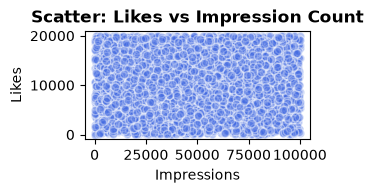

In [21]:
plt.subplot(3, 2, 1)
plt.scatter(df['impression_count'], df['likes'], alpha=0.4, color='royalblue', edgecolor='w')
plt.title('Scatter: Likes vs Impression Count', fontsize=12, fontweight='bold')
plt.xlabel('Impressions')
plt.ylabel('Likes')

(array([18993., 19083., 19174., 19266., 19358., 19448., 19539., 19631.,
        19723.]),
 [Text(18993.0, 0, '2022-01'),
  Text(19083.0, 0, '2022-04'),
  Text(19174.0, 0, '2022-07'),
  Text(19266.0, 0, '2022-10'),
  Text(19358.0, 0, '2023-01'),
  Text(19448.0, 0, '2023-04'),
  Text(19539.0, 0, '2023-07'),
  Text(19631.0, 0, '2023-10'),
  Text(19723.0, 0, '2024-01')])

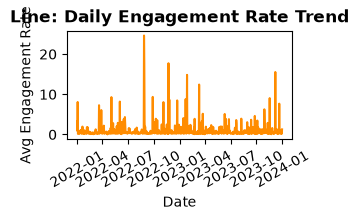

In [22]:
plt.subplot(3, 2, 2)
df['posted_dt'] = pd.to_datetime(df['posted_at'], format='%d-%m-%Y', errors='coerce')
daily_trend = df.groupby('posted_dt')['engagement_rate'].mean().reset_index()
plt.plot(daily_trend['posted_dt'], daily_trend['engagement_rate'], color='darkorange', linewidth=1.5)
plt.title('Line: Daily Engagement Rate Trend', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Avg Engagement Rate')
plt.xticks(rotation=30)

(array([0, 1, 2, 3, 4, 5, 6, 7]),
 [Text(0, 0, 'fitness'),
  Text(1, 0, 'tech'),
  Text(2, 0, 'music'),
  Text(3, 0, 'education'),
  Text(4, 0, 'lifestyle'),
  Text(5, 0, 'travel'),
  Text(6, 0, 'fashion'),
  Text(7, 0, 'food')])

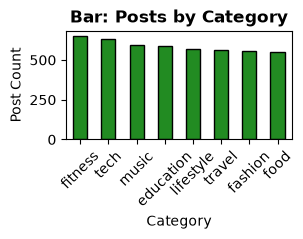

In [23]:
plt.subplot(3, 2, 3)
category_counts = df['post_category'].value_counts()
category_counts.plot(kind='bar', color='forestgreen', edgecolor='black')
plt.title('Bar: Posts by Category', fontsize=12, fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Post Count')
plt.xticks(rotation=45)

Text(0.5, 1.0, 'Pie: Gender Distribution')

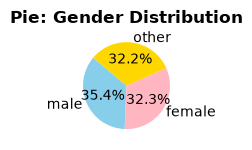

In [24]:
plt.subplot(3, 2, 4)
gender_counts = df['gender'].value_counts()
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=140, colors=['skyblue', 'lightpink', 'gold'])
plt.title('Pie: Gender Distribution', fontsize=12, fontweight='bold')

Text(0, 0.5, 'Frequency')

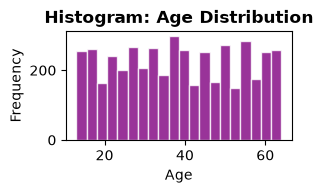

In [25]:
plt.subplot(3, 2, 5)
plt.hist(df['age'].dropna(), bins=20, color='purple', edgecolor='white', alpha=0.8)
plt.title('Histogram: Age Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Frequency')

C:\Users\ACER\AppData\Local\Temp\ipykernel_13000\1056341166.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['engagement_rate'].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor='teal', color='black'))


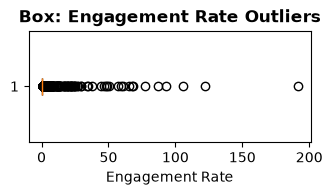

In [26]:
plt.subplot(3, 2, 6)
plt.boxplot(df['engagement_rate'].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor='teal', color='black'))
plt.title('Box: Engagement Rate Outliers', fontsize=12, fontweight='bold')
plt.xlabel('Engagement Rate')

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Count Plot: Post Types')

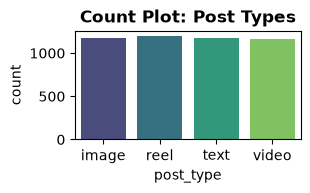

In [27]:
plt.subplot(3, 2, 1)
sns.countplot(data=df, x='post_type', hue='post_type', palette='viridis', legend=False)
plt.title('Count Plot: Post Types', fontsize=12, fontweight='bold')

([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, 'fitness'),
  Text(1, 0, 'food'),
  Text(2, 0, 'tech'),
  Text(3, 0, 'travel'),
  Text(4, 0, 'lifestyle'),
  Text(5, 0, 'education'),
  Text(6, 0, 'music'),
  Text(7, 0, 'fashion')])

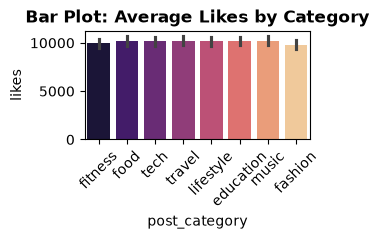

In [28]:
plt.subplot(3, 2, 2)
sns.barplot(data=df, x='post_category', y='likes', hue='post_category', estimator='mean', palette='magma', legend=False)
plt.title('Bar Plot: Average Likes by Category', fontsize=12, fontweight='bold')
plt.xticks(rotation=45)

Text(0.5, 1.0, 'Violin Plot: Followers vs Sentiment')

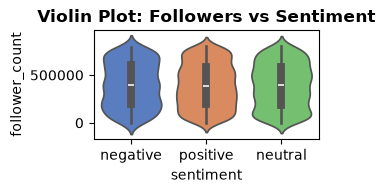

In [29]:
plt.subplot(3, 2, 3)
sns.violinplot(data=df, x='sentiment', y='follower_count', hue='sentiment', palette='muted', legend=False)
plt.title('Violin Plot: Followers vs Sentiment', fontsize=12, fontweight='bold')